<a href="https://colab.research.google.com/github/Josephjiao7/Geographic_moran_effect/blob/main/Case_study_GME.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np

In [ ]:
years = [2008,2012,2016,2020,2024]

files = {
2008:"/content/drive/My Drive/Moran effect/data/data2008.shp",
2012:"/content/drive/My Drive/Moran effect/data/data2012.shp",
2016:"/content/drive/My Drive/Moran effect/data/data2016.shp",
2020:"/content/drive/My Drive/Moran effect/data/data2020.shp",
2024:"/content/drive/My Drive/Moran effect/data/data2024.shp"
}

gdfs = {}

for y in years:
    gdfs[y] = gpd.read_file(files[y]).dropna()

In [ ]:
geoid_sets = [set(gdfs[y]["GEOID"]) for y in years]

common_geoid = set.intersection(*geoid_sets)

print("Common counties:",len(common_geoid))

Common counties: 3099


In [ ]:
gdf_base = gdfs[2024]
gdf_base = gdf_base[gdf_base.GEOID.isin(common_geoid)].copy()

gdf_base = gdf_base.sort_values("GEOID")

In [ ]:
variables = [
"median_age",
"white_shar",
"black_shar",
"hispanic_s",
"college_sh",
"median_inc",
"poverty_ra",
"owner_occu",
"pop_densit",
"unemployme"
]

y_var = "per_gop"

N = len(gdf_base)
T = len(years)
p = len(variables)

y = np.zeros((N,T))
X = np.zeros((N,T,p))

In [ ]:
print("NaN in y:", np.isnan(y).sum())
print("Inf in y:", np.isinf(y).sum())

print("NaN in X:", np.isnan(X).sum())
print("Inf in X:", np.isinf(X).sum())

NaN in y: 0
Inf in y: 0
NaN in X: 2
Inf in X: 0


In [ ]:
print("y finite:", np.isfinite(y).all())
print("X finite:", np.isfinite(X).all())

y finite: True
X finite: False


In [ ]:
mask = (
    np.isfinite(y).all(axis=1) &
    np.isfinite(X).all(axis=(1,2))
)

y = y[mask]
X = X[mask]
gdf_base = gdf_base.iloc[mask]

In [ ]:
for t,year in enumerate(years):

    g = gdfs[year]

    g = g[g.GEOID.isin(common_geoid)]

    g = g.set_index("GEOID").loc[gdf_base.GEOID]

    g[variables] = g[variables].replace("NA", np.nan)

    g[variables] = g[variables].apply(pd.to_numeric, errors="coerce")

    g[y_var] = pd.to_numeric(g[y_var], errors="coerce")

    y[:,t] = g[y_var].values
    X[:,t,:] = g[variables].values

In [ ]:

from libpysal.weights import Queen

w = Queen.from_dataframe(gdf_base)

w.transform = "r"

/tmp/ipykernel_7760/3262583538.py:3: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(gdf_base)


In [ ]:
import scipy.sparse as sp

W = w.sparse

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import inspect
from dataclasses import dataclass

# # ----------------------------
# # Safety checks
# # ----------------------------
# def assert_finite(*arrays, names=None):
#     if names is None:
#         names = [f"arr{i}" for i in range(len(arrays))]
#     for a, nm in zip(arrays, names):
#         if not np.all(np.isfinite(a)):
#             bad = np.sum(~np.isfinite(a))
#             raise ValueError(f"[{nm}] contains non-finite values (NaN/Inf). count={bad}")

def row_standardize(W: sp.csr_matrix) -> sp.csr_matrix:
    W = W.tocsr()
    d = np.asarray(W.sum(axis=1)).ravel()
    d_inv = np.zeros_like(d)
    d_inv[d > 0] = 1.0 / d[d > 0]
    return (sp.diags(d_inv, format="csr") @ W).tocsr()

def laplacian_from_W(W: sp.csr_matrix) -> sp.csr_matrix:
    W = W.tocsr()
    d = np.asarray(W.sum(axis=1)).ravel()
    return (sp.diags(d, format="csr") - W).tocsr()

def rw1_precision(T: int) -> np.ndarray:
    D = np.zeros((T - 1, T))
    for i in range(T - 1):
        D[i, i] = -1.0
        D[i, i + 1] = 1.0
    return D.T @ D

# ----------------------------
# CG wrapper (SciPy API compatible)
# ----------------------------
def cg_solve(A, b, atol=1e-10, rtol=1e-10, maxiter=5000):
    sig = inspect.signature(spla.cg)
    params = sig.parameters
    if "rtol" in params:
        return spla.cg(A, b, atol=atol, rtol=rtol, maxiter=maxiter)
    elif "tol" in params:
        return spla.cg(A, b, atol=atol, tol=rtol, maxiter=maxiter)
    else:
        return spla.cg(A, b, maxiter=maxiter)

# ----------------------------
# Utility
# ----------------------------
def corr_centered(x: np.ndarray, y: np.ndarray) -> float:
    x0, y0 = x - x.mean(), y - y.mean()
    return float((x0 @ y0) / (np.linalg.norm(x0) * np.linalg.norm(y0) + 1e-12))

# ==========================================================
# Two-way within transformation
# ==========================================================

def two_way_within_y(y: np.ndarray) -> np.ndarray:
    """
    Two-way within transformation for outcome:

        y_tilde_st
        =
        y_st
        - y_bar_s.
        - y_bar_.t
        + y_bar_..
    """

    y_unit_mean = y.mean(
        axis=1,
        keepdims=True
    )

    y_time_mean = y.mean(
        axis=0,
        keepdims=True
    )

    y_grand_mean = y.mean()

    y_within = (
        y
        - y_unit_mean
        - y_time_mean
        + y_grand_mean
    )

    return y_within


def two_way_within_X(X: np.ndarray) -> np.ndarray:
    """
    Two-way within transformation for each covariate:

        X_tilde_stk
        =
        X_stk
        - X_bar_s.k
        - X_bar_.tk
        + X_bar_..k
    """

    X_unit_mean = X.mean(
        axis=1,
        keepdims=True
    )

    X_time_mean = X.mean(
        axis=0,
        keepdims=True
    )

    X_grand_mean = X.mean(
        axis=(0, 1),
        keepdims=True
    )

    X_within = (
        X
        - X_unit_mean
        - X_time_mean
        + X_grand_mean
    )

    return X_within


# ==========================================================
# Fit model
# ==========================================================

@dataclass
class FitResult:
    beta: np.ndarray
    a: np.ndarray
    g: np.ndarray
    u: np.ndarray
    resid: np.ndarray
    n_iter: int

    # NEW:
    # transformed variables used by Model 2
    y_within: np.ndarray
    X_within: np.ndarray


def fit_synchrony_factor_model(
    y: np.ndarray,
    X: np.ndarray,
    W: sp.csr_matrix,
    lam_a: float = 10.0,
    lam_g: float = 10.0,
    ridge_beta: float = 1e-3,
    max_iter: int = 200,
    tol: float = 1e-6,
    seed: int = 0,
    cg_maxiter: int = 5000,
    eps_a: float = 1e-4,
    eps_g: float = 1e-8,
    svd_init: bool = True
) -> FitResult:

    rng = np.random.default_rng(seed)

    n, T = y.shape
    p = X.shape[2]

    # ======================================================
    # NEW: Two-way within transformation
    #
    # Remove:
    #   1. additive unit-specific effects
    #   2. additive common temporal effects
    #
    # Estimation below is performed entirely on
    # y_within and X_within.
    # ======================================================

    y_within = two_way_within_y(
        y
    )

    X_within = two_way_within_X(
        X
    )

    # ======================================================
    # Spatial structure
    # ======================================================

    W = W.tocsr()

    # If W is already row-standardized,
    # this operation leaves it effectively unchanged.
    W = row_standardize(
        W
    )

    L = laplacian_from_W(
        W
    ).tocsr()

    Qt = rw1_precision(
        T
    )

    # ======================================================
    # Initial beta using transformed variables
    # ======================================================

    Xv = X_within.reshape(
        n * T,
        p
    )

    Yv = y_within.reshape(
        n * T,
        1
    )

    XtX = (
        Xv.T @ Xv
        + ridge_beta * np.eye(p)
    )

    beta = np.linalg.solve(
        XtX,
        Xv.T @ Yv
    ).ravel()

    # ======================================================
    # Initialize a and g
    # ======================================================

    if svd_init:

        R0 = (
            y_within
            - np.einsum(
                "ntp,p->nt",
                X_within,
                beta
            )
        )

        U, s, Vt = np.linalg.svd(
            R0,
            full_matrices=False
        )

        a = U[:, 0].copy()
        g = Vt[0, :].copy()

        # --------------------------------------------------
        # Temporal factor:
        # mean(g) = 0
        # Var(g) = 1
        # --------------------------------------------------

        g = (
            g
            - g.mean()
        )

        g = (
            g
            /
            (
                g.std(ddof=1)
                + 1e-12
            )
        )

        # --------------------------------------------------
        # NEW:
        # spatial loading centering constraint:
        #
        # mean(a) = 0
        # --------------------------------------------------

        a = (
            a
            - a.mean()
        )

        a = (
            a
            /
            (
                a.std(ddof=1)
                + 1e-12
            )
        )

    else:

        g = rng.normal(
            size=T
        )

        g = (
            g
            - g.mean()
        )

        g = (
            g
            /
            (
                g.std(ddof=1)
                + 1e-12
            )
        )

        a = rng.normal(
            size=n
        )

        # NEW
        a = (
            a
            - a.mean()
        )

    # ======================================================
    # Alternating minimization
    # ======================================================

    I_n = sp.eye(
        n,
        format="csr"
    )

    for it in range(
        max_iter
    ):

        # ==================================================
        # Partial residual after transformed X beta
        #
        # R_st =
        # y_tilde_st - X_tilde_st beta
        # ==================================================

        R = (
            y_within
            - np.einsum(
                "ntp,p->nt",
                X_within,
                beta
            )
        )

        # ==================================================
        # Update spatial loading a
        #
        # (||g||^2 I + lambda_a L + eps I)a
        # =
        # Rg
        # ==================================================

        g2 = float(
            np.sum(
                g ** 2
            )
        )

        rhs_a = (
            R @ g
        )

        A_a = (
            g2 * I_n
            + lam_a * L
            + eps_a * I_n
        ).tocsr()

        a_new, info = cg_solve(
            A_a,
            rhs_a,
            atol=1e-10,
            rtol=1e-10,
            maxiter=cg_maxiter
        )

        if info != 0:

            a_new = spla.spsolve(
                A_a.tocsc(),
                rhs_a
            )

        # ==================================================
        # NEW:
        # enforce mean(a) = 0
        #
        # Loading therefore captures geographically
        # differentiated sensitivity relative to the
        # system-wide mean response.
        # ==================================================

        a_new = (
            a_new
            - a_new.mean()
        )

        # ==================================================
        # Update temporal factor g
        # ==================================================

        a2 = float(
            np.sum(
                a_new ** 2
            )
        )

        rhs_g = (
            a_new[:, None]
            * R
        ).sum(
            axis=0
        )

        A_g = (
            a2 * np.eye(T)
            + lam_g * Qt
            + eps_g * np.eye(T)
        )

        g_new = np.linalg.solve(
            A_g,
            rhs_g
        )

        # ==================================================
        # Normalize g:
        #
        # mean(g) = 0
        # Var(g) = 1
        #
        # absorb scale into a
        # ==================================================

        g_new = (
            g_new
            - g_new.mean()
        )

        scale_g = (
            g_new.std(
                ddof=1
            )
            + 1e-12
        )

        g_new = (
            g_new
            / scale_g
        )

        a_new = (
            a_new
            * scale_g
        )

        # Numerical enforcement of spatial centering
        a_new = (
            a_new
            - a_new.mean()
        )

        # ==================================================
        # Convergence for a and g
        # ==================================================

        da = (
            np.linalg.norm(
                a_new - a
            )
            /
            (
                np.linalg.norm(a)
                + 1e-12
            )
        )

        dg = (
            np.linalg.norm(
                g_new - g
            )
            /
            (
                np.linalg.norm(g)
                + 1e-12
            )
        )

        a = a_new
        g = g_new

        # ==================================================
        # Refit beta conditional on estimated GME
        #
        # beta =
        # argmin ||y_tilde - u - X_tilde beta||^2
        # ==================================================

        u_hat = np.outer(
            a,
            g
        )

        Yv2 = (
            y_within
            - u_hat
        ).reshape(
            n * T,
            1
        )

        beta_new = np.linalg.solve(
            XtX,
            Xv.T @ Yv2
        ).ravel()

        db = (
            np.linalg.norm(
                beta_new - beta
            )
            /
            (
                np.linalg.norm(beta)
                + 1e-12
            )
        )

        beta = beta_new

        # ==================================================
        # Stop criterion
        # ==================================================

        if max(
            da,
            dg,
            db
        ) < tol:

            break

    # ======================================================
    # Final estimates
    # ======================================================

    u_hat = np.outer(
        a,
        g
    )

    resid = (
        y_within
        - np.einsum(
            "ntp,p->nt",
            X_within,
            beta
        )
        - u_hat
    )

    return FitResult(
        beta=beta,
        a=a,
        g=g,
        u=u_hat,
        resid=resid,
        n_iter=it + 1,
        y_within=y_within,
        X_within=X_within
    )


# ==========================================================
# Fit
# ==========================================================

fit = fit_synchrony_factor_model(
    y=y,
    X=X,
    W=W,
    lam_a=10.0,
    lam_g=10.0,
    ridge_beta=1e-3,
    max_iter=200,
    tol=1e-6,
    seed=0,
    eps_a=1e-10,
    eps_g=1e-8,
    svd_init=True
)

print(
    "Iterations:",
    fit.n_iter
)


# ==========================================================
# Extract estimates
# ==========================================================

a_hat = fit.a
g_hat = fit.g
u_hat = fit.u
resid = fit.resid


# ==========================================================
# NEW:
# MEI must be defined relative to the transformed variation
# identified by revised Model 2.
#
# Do NOT use:
#
#     np.var(y, axis=1)
#
# here anymore.
# ==========================================================

var_y = np.var(
    fit.y_within,
    axis=1,
    ddof=1
)

mei = (
    np.var(
        u_hat,
        axis=1,
        ddof=1
    )
    /
    (
        var_y
        + 1e-12
    )
)


# ==========================================================
# Absolute GME effect
# ==========================================================

abs_hat = np.mean(
    np.abs(
        u_hat
    ),
    axis=1
)


# ==========================================================
# Output
# ==========================================================

gdf_base["loading"] = a_hat
gdf_base["MEI"] = mei
gdf_base["abs"] = abs_hat

gdf_base["resid_var"] = np.var(
    resid,
    axis=1,
    ddof=1
)

gdf_base = gdf_base.to_crs(
    "+proj=lcc "
    "+lat_1=33 "
    "+lat_2=45 "
    "+lat_0=39 "
    "+lon_0=-96 "
    "+x_0=0 "
    "+y_0=0 "
    "+datum=WGS84 "
    "+units=m "
    "+no_defs"
)

gdf_out = gdf_base[
    [
        "GEOID",
        "loading",
        "MEI",
        "abs",
        "geometry"
    ]
]

gdf_out.to_file(
    "/content/drive/My Drive/Moran effect/moran_effect_results.shp",
    driver="ESRI Shapefile"
)


Iterations: 8


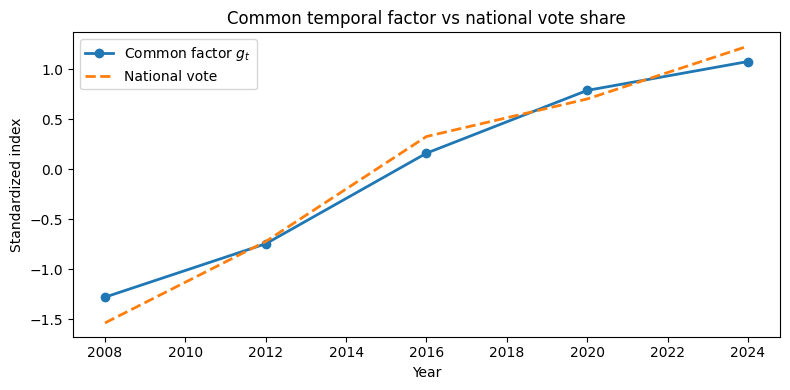

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 年份
years = np.array(years)

# common factor
g_hat = fit.g

# national vote share
national_vote_share = y.mean(axis=0)

# 标准化方便比较
national_vote_share = (
    national_vote_share - national_vote_share.mean()
) / national_vote_share.std()

plt.figure(figsize=(8,4))

plt.plot(years, g_hat, marker='o', linewidth=2, label="Common factor $g_t$")
plt.plot(years, national_vote_share, '--', linewidth=2, label="National vote")

plt.legend()
plt.xlabel("Year")
plt.ylabel("Standardized index")
plt.title("Common temporal factor vs national vote share")

plt.tight_layout()
plt.show()

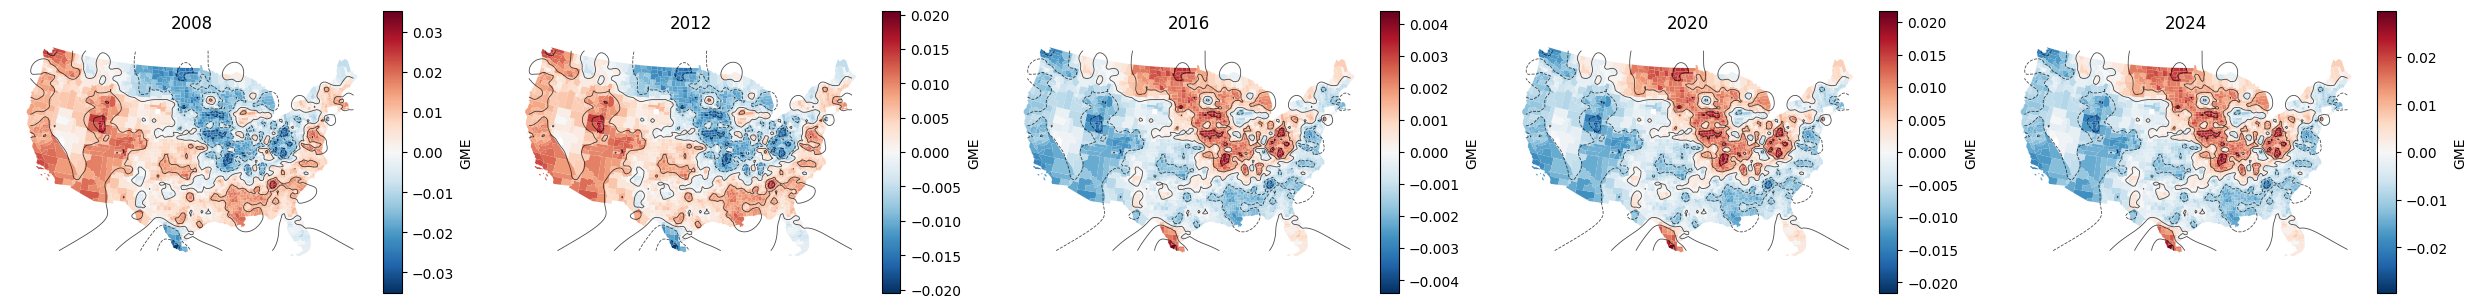

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.interpolate import Rbf
from matplotlib.colors import TwoSlopeNorm


gdf_base = gdf_base.reset_index(drop=True)
gdf_proj = gdf_base.to_crs(epsg=5070)

# centroid
gdf_proj["centroid"] = gdf_proj.geometry.centroid
gdf_proj["x"] = gdf_proj.centroid.x
gdf_proj["y_coord"] = gdf_proj.centroid.y

coords = gdf_proj[["x", "y_coord"]].values


grid_res = 150

xi = np.linspace(coords[:,0].min(), coords[:,0].max(), grid_res)
yi = np.linspace(coords[:,1].min(), coords[:,1].max(), grid_res)
Xi, Yi = np.meshgrid(xi, yi)


years = [2008, 2012, 2016, 2020, 2024]
t_list = list(range(len(years)))

fig, axes = plt.subplots(1, len(t_list), figsize=(25, 5))

for i, t in enumerate(t_list):

    Z = u_hat[:, t]
    ax = axes[i]

    vmax = np.max(np.abs(Z))
    vmin = -vmax
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)


    gdf_proj["val"] = Z
    gdf_proj.plot(
        column="val",
        cmap="RdBu_r",
        norm=norm,
        linewidth=0,
        ax=ax
    )

    # -------------------------
    # 2. RBF
    # -------------------------
    rbf = Rbf(
        coords[:,0],
        coords[:,1],
        Z,
        function='linear',
        smooth=2.0
    )

    Zi = rbf(Xi, Yi)


    levels = np.linspace(vmin, vmax, 7)

    ax.contour(
        Xi, Yi, Zi,
        levels=levels,
        colors='black',
        linewidths=0.6,
        alpha=0.7
    )


    ax.set_title(str(years[t]))
    ax.axis("off")


    sm = plt.cm.ScalarMappable(
        cmap='RdBu_r',
        norm=norm
    )
    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=ax,
        shrink=0.6,
        aspect=15,
        pad=0.02
    )
    cbar.set_label("GME")


plt.tight_layout(w_pad=1.0)

plt.savefig("/content/drive/My Drive/Moran effect/picture/Moran_effect_final1.png", dpi=600)
# plt.show()